In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Configuracion de estilo grafico
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (13, 8)
plt.rcParams['font.size'] = 11

print("Librerías importadas exitosamente:")
print(f"- NumPy: {np.__version__}")
import scipy
print(f"- SciPy: {scipy.__version__}")

Librerías importadas exitosamente:
- NumPy: 2.5.3
- SciPy: 1.18.1


In [6]:
# 1.1 Base temporal
fs = 1000.0          # Frecuencia de muestreo [Hz]
duracion = 2.0        # Duracion de la ventana [s]
t = np.linspace(0, duracion, int(fs * duracion), endpoint=False)

# 1.2 Senal fisica util (Vibracion real: 2 Hz y 7 Hz)
s_util = 1.5 * np.sin(2 * np.pi * 2 * t) + 0.8 * np.cos(2 * np.pi * 7 * t)

# 1.3 Componentes contaminantes
ruido_50hz = 1.2 * np.sin(2 * np.pi * 50 * t)       # Ruido de red
ruido_120hz = 0.6 * np.sin(2 * np.pi * 120 * t)     # Inversor industrial
np.random.seed(42)                                  # Semilla fija para reproducibilidad
ruido_gauss = np.random.normal(0, 0.3, len(t))      # Ruido termico blanco

# Senal contaminada que ingresa al ADC
s_ruidosa = s_util + ruido_50hz + ruido_120hz + ruido_gauss

print(f"Muestras capturadas: N = {len(t)}")
print(f"Rango de amplitud ruidosa: [{s_ruidosa.min():.2f} V, {s_ruidosa.max():.2f} V]")

Muestras capturadas: N = 2000
Rango de amplitud ruidosa: [-4.58 V, 4.07 V]


In [7]:
N = len(t)
# Vector de frecuencias positivas [Hz] desde 0 hasta fs/2 (500 Hz)
freqs = np.fft.rfftfreq(N, d=1.0 / fs)

# Magnitud normalizada del espectro
fft_ruidosa = np.abs(np.fft.rfft(s_ruidosa)) / N

print(f"Resolución frecuencial: Delta f = {fs / N:.2f} Hz por bin")
print(f"Frecuencia máxima analizada (Nyquist): {freqs.max():.1f} Hz")

Resolución frecuencial: Delta f = 0.50 Hz por bin
Frecuencia máxima analizada (Nyquist): 500.0 Hz


In [8]:
# =============================================================================
# ETAPA A: Filtro Notch a 50 Hz
# =============================================================================
f_notch = 50.0  # Frecuencia a eliminar [Hz]
Q = 30.0        # Factor de calidad (Delta_f = 50 / 30 = 1.67 Hz)
b_notch, a_notch = signal.iirnotch(w0=f_notch, Q=Q, fs=fs)

# Primera pasada: Supresion de red con fase cero
s_sin_50hz = signal.filtfilt(b_notch, a_notch, s_ruidosa)

# =============================================================================
# ETAPA B: Filtro Pasa-Bajos Butterworth a 20 Hz
# =============================================================================
fc = 20.0             # Frecuencia de corte [Hz]
f_nyquist = 0.5 * fs  # 500 Hz
Wn = fc / f_nyquist   # Frecuencia de corte normalizada
b_low, a_low = signal.butter(N=4, Wn=Wn, btype='low')

# Segunda pasada: Limpieza final en cascada
s_filtrada = signal.filtfilt(b_low, a_low, s_sin_50hz)

# Recalculo de la FFT de la senal filtrada
fft_filtrada = np.abs(np.fft.rfft(s_filtrada)) / N

print("Cascada de filtros aplicada exitosamente con scipy.signal.filtfilt.")

Cascada de filtros aplicada exitosamente con scipy.signal.filtfilt.


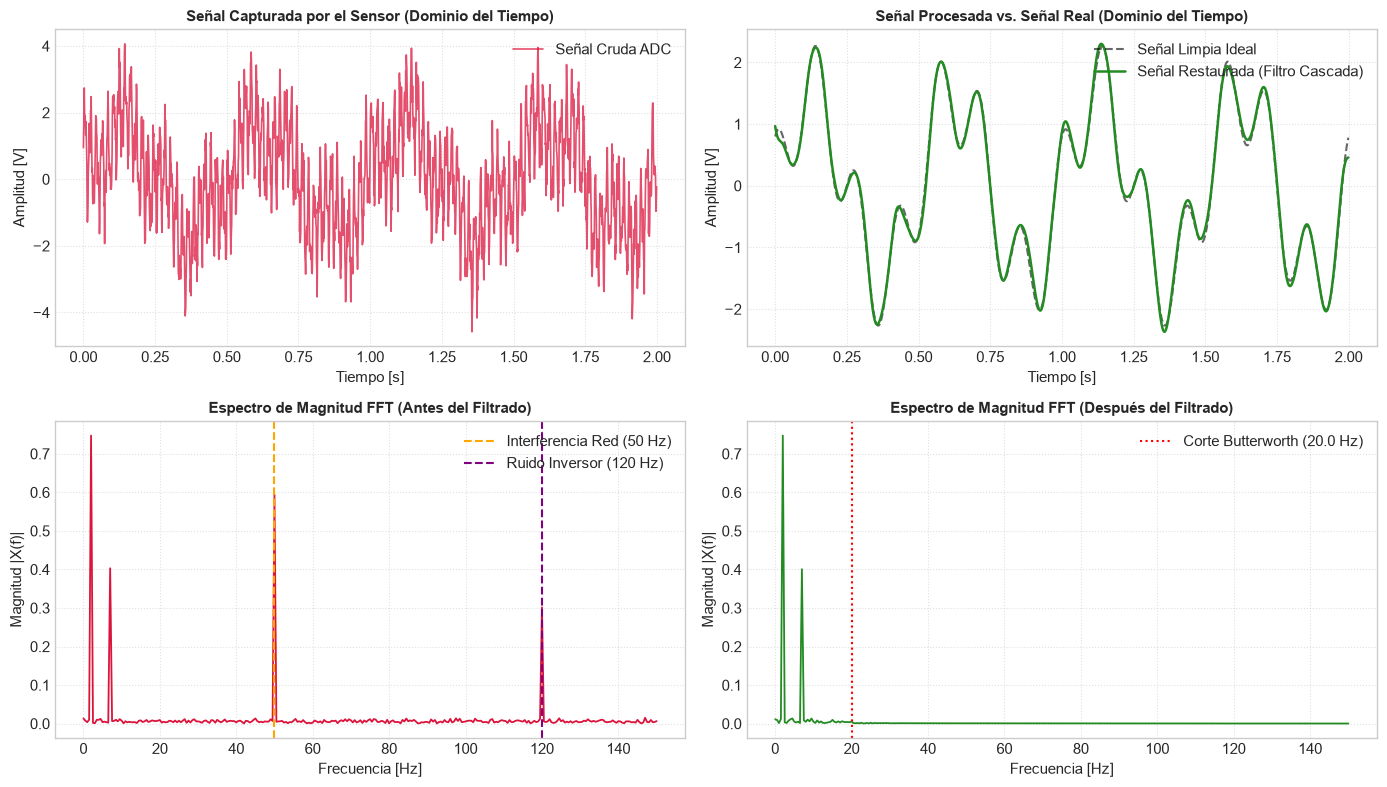

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8))
f_max_plot = 150.0  # Limite superior de visualizacion en frecuencia [Hz]
mask = freqs <= f_max_plot

# -----------------------------------------------------------------------------
# Panel Superior Izquierdo: Tiempo - Senal Ruidosa
# -----------------------------------------------------------------------------
axs[0, 0].plot(t, s_ruidosa, color='crimson', alpha=0.75, lw=1.2, label='Señal Cruda ADC')
axs[0, 0].set_title('Señal Capturada por el Sensor (Dominio del Tiempo)', fontsize=11, fontweight='bold')
axs[0, 0].set_xlabel('Tiempo [s]')
axs[0, 0].set_ylabel('Amplitud [V]')
axs[0, 0].grid(True, linestyle=':', alpha=0.6)
axs[0, 0].legend(loc='upper right')

# -----------------------------------------------------------------------------
# Panel Superior Derecho: Tiempo - Senal Restaurada vs Ideal
# -----------------------------------------------------------------------------
axs[0, 1].plot(t, s_util, 'k--', lw=1.5, alpha=0.6, label='Señal Limpia Ideal')
axs[0, 1].plot(t, s_filtrada, color='forestgreen', lw=1.8, label='Señal Restaurada (Filtro Cascada)')
axs[0, 1].set_title('Señal Procesada vs. Señal Real (Dominio del Tiempo)', fontsize=11, fontweight='bold')
axs[0, 1].set_xlabel('Tiempo [s]')
axs[0, 1].set_ylabel('Amplitud [V]')
axs[0, 1].grid(True, linestyle=':', alpha=0.6)
axs[0, 1].legend(loc='upper right')

# -----------------------------------------------------------------------------
# Panel Inferior Izquierdo: Frecuencia - Espectro Ruidoso
# -----------------------------------------------------------------------------
axs[1, 0].plot(freqs[mask], fft_ruidosa[mask], color='crimson', lw=1.3)
axs[1, 0].axvline(50, color='orange', linestyle='--', lw=1.5, label='Interferencia Red (50 Hz)')
axs[1, 0].axvline(120, color='purple', linestyle='--', lw=1.5, label='Ruido Inversor (120 Hz)')
axs[1, 0].set_title('Espectro de Magnitud FFT (Antes del Filtrado)', fontsize=11, fontweight='bold')
axs[1, 0].set_xlabel('Frecuencia [Hz]')
axs[1, 0].set_ylabel('Magnitud |X(f)|')
axs[1, 0].grid(True, linestyle=':', alpha=0.6)
axs[1, 0].legend(loc='upper right')
# -----------------------------------------------------------------------------
# Panel Inferior Derecho: Frecuencia - Espectro Restaurado
# -----------------------------------------------------------------------------
axs[1, 1].plot(freqs[mask], fft_filtrada[mask], color='forestgreen', lw=1.3)
axs[1, 1].axvline(fc, color='red', linestyle=':', lw=1.5, label=f'Corte Butterworth ({fc} Hz)')
axs[1, 1].set_title('Espectro de Magnitud FFT (Después del Filtrado)', fontsize=11, fontweight='bold')
axs[1, 1].set_xlabel('Frecuencia [Hz]')
axs[1, 1].set_ylabel('Magnitud |X(f)|')
axs[1, 1].grid(True, linestyle=':', alpha=0.6)
axs[1, 1].legend(loc='upper right')

plt.tight_layout()
plt.show()